# 01 · Exploración de datos (EDA) de la OBT

| | |
|---|---|
| **Entrega** | PSet 3, sección 1 de `CD_PSet_3.pdf` (EDA y features: 15 %) |
| **Autor** | Allan Paul Gómez Ehmig (00351916) |
| **Datos** | snapshot de `PORTAFOLIO_P3.OBT.OBT_ACCION_MES` (`data/obt.parquet`; su sha256 se imprime abajo) |
| **Problema** | regresión: retorno log de cada acción el mes siguiente (`ret_log_mes_siguiente`), para elegir qué acciones comprar al cierre de cada mes |
| **Datos que se miran** | solo **entrenamiento**: filas elegibles cuyo objetivo termina antes de 2024. El hold-out (desde 2024-01) no se abre aquí |

Cómo correrlo: *Restart + Run All* desde `psets/pset-03` o `notebooks/`. Si falta el snapshot:
`uv run python -m src.datos`.

### Qué pide el PDF y dónde está

| Requisito | Sección |
|---|---|
| Tamaño, tipos de datos y faltantes por columna | 1 y 2 |
| Estadística descriptiva | 3 |
| Distribución del target y sus características | 4 |
| Atípicos con IQR (diagrama de caja) y Z-score ≥ 3 | 5 |
| Relación target–features con Pearson o Spearman, justificada | 6 |
| Matriz de varianza-covarianza de las columnas de la OBT (pedido de Paul) | 6b |
| Matriz de varianza-covarianza de las variables normalizadas (pedido de Paul) | 6c |
| Desbalance de clases (si es clasificación) | 7 |
| Al menos 3 hallazgos: hallazgo, evidencia, consecuencia en el modelo | 9 |

La calidad de cada capa del pipeline está en `pipeline/docs/calidad/analisis_calidad_pipeline.ipynb`;
aquí se resume lo que llega a la OBT (sección 8).

In [1]:
# Carga del snapshot, preparación (src/pipeline.py) y división temporal; el hold-out queda reservado.
import sys, warnings, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

RAIZ = Path.cwd().resolve()
RAIZ = RAIZ.parent if RAIZ.name == 'notebooks' else RAIZ
sys.path.insert(0, str(RAIZ))
from src.datos import cargar
from src.pipeline import (preparar, dividir, EXCLUIDAS, FEATURES_OBT, BASE, F1_LOG, F1_PCT, DERIVADAS, FUGA,
                          TARGET, OBT_MES_PSET2, OBT_MES_F1)
from src.modelos.tabulares import DE_MERCADO

warnings.filterwarnings('ignore', category=stats.ConstantInputWarning)
pd.set_option('display.max_rows', 120); pd.set_option('display.width', 200)
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True, 'grid.alpha': 0.3})
FIG = RAIZ / 'docs/figuras'; FIG.mkdir(parents=True, exist_ok=True)
def guardar(fig, nombre):
    fig.savefig(FIG / f'eda_{nombre}.png', dpi=130, bbox_inches='tight')

FEATURES = FEATURES_OBT             # el EDA mira los 33 predictores de la OBT; las derivadas se disenan en 02
obt, meta = cargar()
datos = preparar(obt)               # elegibles con objetivo + derivadas (notebook 02)
train, holdout = dividir(datos)     # corte en el tiempo: objetivo hasta 2023-12 / desde 2024-01; luego interpola huecos
y = train[TARGET]
print(json.dumps({'tabla': meta['tabla'], 'sha256': meta['sha256'][:16], 'snapshot_utc': meta['snapshot_utc'][:19],
                  'filas_obt': len(obt), 'columnas_obt': obt.shape[1], 'elegibles_con_objetivo': len(datos),
                  'entrenamiento': len(train), 'holdout_reservado': len(holdout),
                  'meses_entrenamiento': f'{train.anio_mes.min()}..{train.anio_mes.max()} ({train.anio_mes.nunique()})'}, indent=1))

{
 "tabla": "PORTAFOLIO_P3.OBT.OBT_ACCION_MES",
 "sha256": "c356891723976bce",
 "snapshot_utc": "2026-11-18T05:21:27",
 "filas_obt": 87178,
 "columnas_obt": 75,
 "elegibles_con_objetivo": 58177,
 "entrenamiento": 46851,
 "holdout_reservado": 11326,
 "meses_entrenamiento": "201010..202311 (158)"
}


## 1. Tamaño y tipos de datos

La OBT tiene una fila por acción y mes cerrado. No todas las filas sirven para modelar: `elegible` exige que
la acción esté en el S&P 500 ese mes, cotice en la NYSE (o tenga bolsa desconocida, para no reintroducir
sesgo de supervivencia), haya cotizado al cierre, tenga ≥ 200 días de historia y ≥ 15 días negociados en el mes.

,filas,meses,acciones
OBT completa,87178,202,608
elegibles,58627,193,413
elegibles con objetivo,58177,192,400
entrenamiento,46851,158,380
hold-out (reservado),11326,34,350


origen,F1 (PSet 3),PSet 2,total
uso,,,
"clave, atributo o control",0,16,16
misma variable en % (EDA),15,0,15
nunca predictor (fuga),1,9,10
objetivo,0,1,1
predictor,16,17,33
total,32,43,75


tipo,bool,float64,int16,int32,int8,object,str
columnas,9,54,2,1,3,1,5


Predictores de la OBT: 33 = 17 del PSet 2 + 16 de F1 (log); derivadas disenadas en 02_features: 12 (dispersion_mes y el mes calendario del objetivo en one-hot)


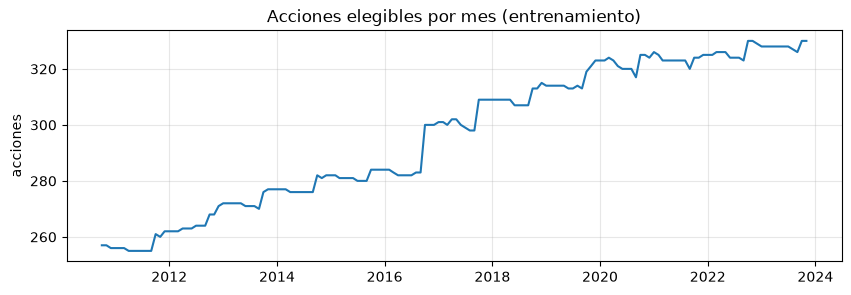

Acciones por mes: min 255, mediana 300, max 330


In [2]:
# Tamaño por etapa y tipos de las 75 columnas, agrupadas por origen (PSet 2 / F1) y uso en el modelo.
etapas = pd.DataFrame({'filas': [len(obt), int(obt.elegible.fillna(False).sum()), len(datos), len(train), len(holdout)],
                       'meses': [obt.anio_mes.nunique(), obt[obt.elegible.fillna(False)].anio_mes.nunique(),
                                 datos.anio_mes.nunique(), train.anio_mes.nunique(), holdout.anio_mes.nunique()],
                       'acciones': [obt.accion_key.nunique(), obt[obt.elegible.fillna(False)].accion_key.nunique(),
                                    datos.accion_key.nunique(), train.accion_key.nunique(), holdout.accion_key.nunique()]},
                      index=['OBT completa', 'elegibles', 'elegibles con objetivo', 'entrenamiento', 'hold-out (reservado)'])
display(etapas)

def uso(c):
    if c == TARGET: return 'objetivo'
    if c in FUGA: return 'nunca predictor (fuga)'
    if c in FEATURES_OBT: return 'predictor'
    if c in F1_PCT: return 'misma variable en % (EDA)'
    return 'clave, atributo o control'
tipos = pd.DataFrame({'tipo': obt.dtypes.astype(str), 'origen': ['F1 (PSet 3)' if c in OBT_MES_F1 else 'PSet 2' for c in obt],
                      'uso': [uso(c) for c in obt]})
display(pd.crosstab(tipos.uso, tipos.origen, margins=True, margins_name='total'))
display(tipos.groupby('tipo').size().rename('columnas').to_frame().T)
print(f'Predictores de la OBT: {len(FEATURES)} = {len(BASE)} del PSet 2 + {len(F1_LOG)} de F1 (log); '
      f'derivadas disenadas en 02_features: {len(DERIVADAS)} ({DERIVADAS[0]} y el mes calendario del objetivo en one-hot)')

n_mes = train.groupby('anio_mes').size()
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(pd.PeriodIndex(n_mes.index.astype(str), freq='M').to_timestamp(), n_mes.values)
ax.set_title('Acciones elegibles por mes (entrenamiento)'); ax.set_ylabel('acciones'); guardar(fig, 'acciones_por_mes'); plt.show()
print(f'Acciones por mes: min {n_mes.min()}, mediana {int(n_mes.median())}, max {n_mes.max()}')

## 2. Valores faltantes por columna

Se miden en dos lugares: en toda la OBT (incluye filas no elegibles, el inicio de la historia y el último mes
sin objetivo) y en el conjunto de entrenamiento, que es lo que ve el modelo.

37 de 75 columnas tienen algun nulo en la OBT completa:


,pct_obt,pct_entrenamiento,uso
ret_pct_mes_lag3,2.121,0.000,misma variable en % (EDA)
ret_log_mes_lag3,2.121,0.000,predictor
ret_pct_mes_lag2,1.417,0.000,misma variable en % (EDA)
ret_log_mes_lag2,1.417,0.000,predictor
cambio_rango_pct_hl_mes,0.740,0.000,misma variable en % (EDA)
exceso_ret_mes_siguiente,0.711,0.000,nunca predictor (fuga)
cambio_rango_log_hl_mes,0.711,0.000,predictor
ret_pct_mes_lag1,0.711,0.000,misma variable en % (EDA)
ret_log_mes_lag1,0.711,0.000,predictor
ret_pct_mes_siguiente,0.711,0.000,nunca predictor (fuga)


En entrenamiento, 0 de 34 predictores/objetivo tienen nulos: ninguno


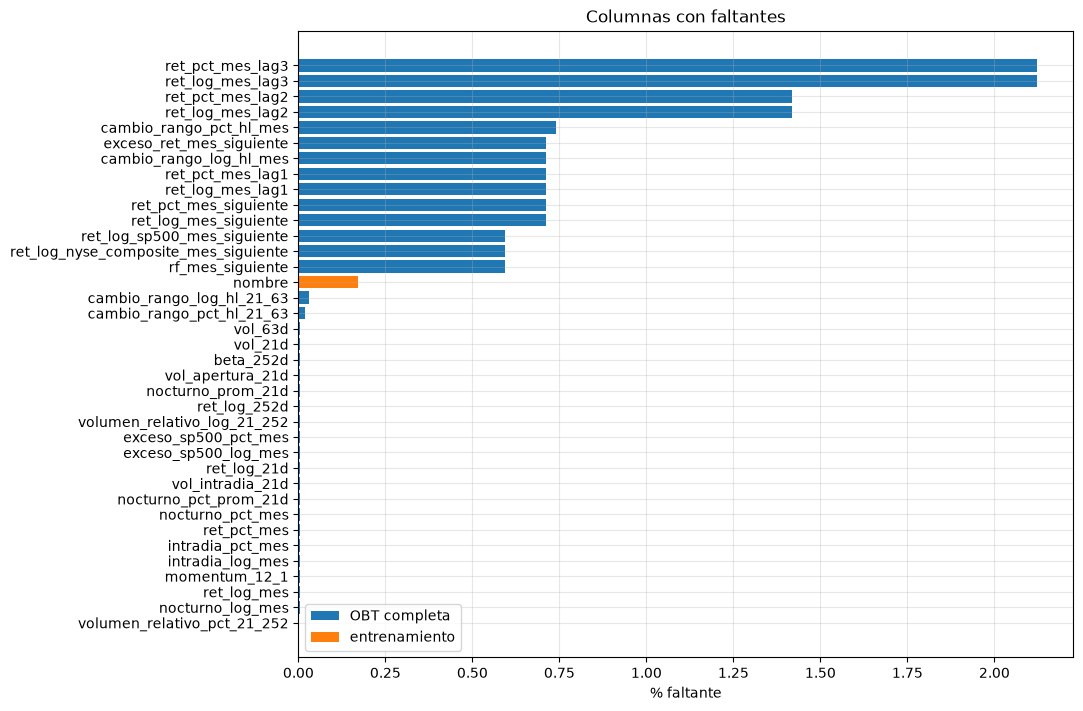

In [3]:
# Faltantes por columna: OBT completa vs entrenamiento (predictores y objetivo).
falt = pd.DataFrame({'pct_obt': obt.isna().mean() * 100})
falt['pct_entrenamiento'] = pd.Series({c: train[c].isna().mean() * 100 for c in obt.columns if c in train})
falt['uso'] = [uso(c) for c in falt.index]
con = falt[falt.pct_obt > 0].sort_values('pct_obt', ascending=False).round(3)
print(f'{len(con)} de {len(falt)} columnas tienen algun nulo en la OBT completa:')
display(con)
f_tr = train[FEATURES + [TARGET]].isna().mean().mul(100)
print(f'En entrenamiento, {int((f_tr > 0).sum())} de {len(f_tr)} predictores/objetivo tienen nulos: '
      f"{f_tr[f_tr > 0].round(4).to_dict() or 'ninguno'}")
fig, ax = plt.subplots(figsize=(10, max(3, 0.22 * len(con))))
ax.barh(con.index[::-1], con.pct_obt[::-1], label='OBT completa')
ax.barh(con.index[::-1], con.pct_entrenamiento.fillna(0)[::-1], label='entrenamiento')
ax.set_xlabel('% faltante'); ax.legend(); ax.set_title('Columnas con faltantes'); guardar(fig, 'faltantes'); plt.show()

In [4]:
# Exclusiones y faltantes de los predictores antes y despues de interpolar, a cada lado del corte.
import pandas as _pd
ex = obt[obt.ticker.astype(str).str.upper().isin(EXCLUIDAS) & obt.elegible.fillna(False).astype(bool)]
print(f'Excluidas {EXCLUIDAS}: {len(ex)} filas elegibles de la OBT ({ex.anio_mes.min()}..{ex.anio_mes.max()})')
corte = _pd.Period('2023-12', freq='M')
crudo = {'entrenamiento': datos[datos.mes_objetivo <= corte], 'hold-out': datos[datos.mes_objetivo > corte]}
final = {'entrenamiento': train, 'hold-out': holdout}
resumen = _pd.DataFrame({k: {'filas': len(final[k]),
                             'nulos antes de interpolar': int(crudo[k][FEATURES].isna().sum().sum()),
                             'nulos tras interpolar (van a la mediana)': int(final[k][FEATURES].isna().sum().sum())}
                         for k in final}).T
display(resumen)

Excluidas ('BMS', 'AMCR'): 109 filas elegibles de la OBT (201303..202610)


,filas,nulos antes de interpolar,nulos tras interpolar (van a la mediana)
entrenamiento,46851,0,0
hold-out,11326,0,0


**Lectura.** Los nulos de la OBT completa se concentran en columnas que por construcción no existen en algunas
filas: las del mes siguiente (último mes cerrado), las ventanas largas al inicio de cada acción y los atributos
actuales de acciones que ya no cotizan. `elegible` (historia ≥ 200 días, volumen > 0) los elimina casi todos.

**Cómo se tratan los faltantes de los predictores** (`src/pipeline.py`).
- `BMS` y `AMCR` quedan fuera (`EXCLUIDAS`, H19): la semilla de equivalencias une Bemis con Amcor como si
  fuera un cambio de símbolo y AMCR 2012–2014 trae barras de solo cierre (rango 0, volumen casi nulo), que
  dejaban predictores 0/0.
- **Huecos intermedios**: se interpolan linealmente por acción, en orden de mes, entre el último valor observado
  antes y el primero después (`interpolar_huecos`).
- **Faltantes al inicio o al final** de la historia de una acción (sin vecino a un lado): mediana dentro del
  Pipeline, ajustada en cada pliegue solo con su entrenamiento.
- La separación es un **corte en el tiempo** (objetivo hasta 2023-12 en entrenamiento) y se hace **antes** de
  interpolar: cada lado se interpola con sus propios meses, así ningún mes del hold-out rellena el entrenamiento.
  Todo el EDA, incluidas las matrices de las secciones 6b y 6c, usa solo el entrenamiento.

## 3. Estadística descriptiva

Sobre entrenamiento. Además de `describe()`, asimetría y curtosis en exceso (normal: 0 y 0), que anticipan
colas y la elección de métricas y transformaciones.

In [5]:
# Descriptivos de los 33 predictores de la OBT y el objetivo, con asimetría y curtosis.
desc = train[FEATURES + [TARGET]].describe(percentiles=[.01, .25, .5, .75, .99]).T
desc['asimetria'] = train[FEATURES + [TARGET]].skew(); desc['curtosis_exceso'] = train[FEATURES + [TARGET]].kurt()
desc['grupo'] = ['objetivo' if c == TARGET else 'F1' if c in F1_LOG else 'derivada' if c in DERIVADAS else 'PSet 2'
                 for c in desc.index]
with pd.option_context('display.float_format', '{:,.4f}'.format):
    display(desc[['grupo', 'count', 'mean', 'std', 'min', '1%', '25%', '50%', '75%', '99%', 'max', 'asimetria', 'curtosis_exceso']])
print('Mayor curtosis:', desc.curtosis_exceso.sort_values(ascending=False).head(5).round(1).to_dict())

,grupo,count,mean,std,min,1%,25%,50%,75%,99%,max,asimetria,curtosis_exceso
ret_log_mes,PSet 2,"46,851.0000",0.0073,0.0819,-1.2237,-0.2222,-0.0344,0.0117,0.0530,0.2027,0.5904,-1.0156,9.6484
ret_log_21d,PSet 2,"46,851.0000",0.0074,0.0825,-1.1778,-0.2274,-0.0339,0.0122,0.0533,0.2019,0.5904,-1.0852,9.8429
ret_log_252d,PSet 2,"46,851.0000",0.0939,0.2570,-1.6779,-0.6502,-0.0399,0.1096,0.2468,0.7115,1.6575,-0.4759,2.5479
momentum_12_1,PSet 2,"46,851.0000",0.0865,0.2468,-1.7498,-0.6155,-0.0422,0.1015,0.2323,0.6843,1.8250,-0.4516,2.6357
vol_21d,PSet 2,"46,851.0000",0.2598,0.1627,0.0385,0.0872,0.1650,0.2223,0.3049,0.9246,3.0182,4.0007,29.7818
vol_63d,PSet 2,"46,851.0000",0.2694,0.1450,0.0637,0.1073,0.1830,0.2351,0.3082,0.8550,2.1958,3.1378,16.7970
vol_apertura_21d,PSet 2,"46,851.0000",0.2597,0.1538,0.0513,0.0890,0.1652,0.2226,0.3069,0.8549,3.0661,3.4395,23.9090
intradia_prom_21d,PSet 2,"46,851.0000",0.0001,0.0033,-0.0688,-0.0085,-0.0017,0.0002,0.0020,0.0080,0.0231,-0.8114,10.6069
nocturno_prom_21d,PSet 2,"46,851.0000",0.0003,0.0024,-0.0340,-0.0072,-0.0006,0.0003,0.0013,0.0061,0.0259,-1.4668,17.0138
drawdown_252d,PSet 2,"46,851.0000",-0.1165,0.1200,-0.8392,-0.5319,-0.1682,-0.0790,-0.0265,0.0000,0.0000,-1.6214,3.0261


Mayor curtosis: {'volumen_prom_21d': 262.9, 'dolares_negociados_prom_21d': 100.1, 'obs_252d': 81.8, 'cambio_rango_log_hl_mes': 46.8, 'vol_garman_klass_21d': 37.2}


## 4. Distribución del target

`ret_log_mes_siguiente` es el retorno logarítmico de la acción el mes siguiente al cierre. Se compara con una
normal de igual media y desviación, y se mira cómo cambia en el tiempo: en un panel acción × mes, parte de la
variación es común a todas las acciones del mes (el mercado) y parte es propia de cada acción.

,valor
cuantil 0.01,-0.2227
cuantil 0.05,-0.1221
cuantil 0.25,-0.0343
cuantil 0.5,0.0119
cuantil 0.75,0.0534
cuantil 0.95,0.1268
cuantil 0.99,0.2035
n,46851.0000
media,0.0076
desviacion,0.0821


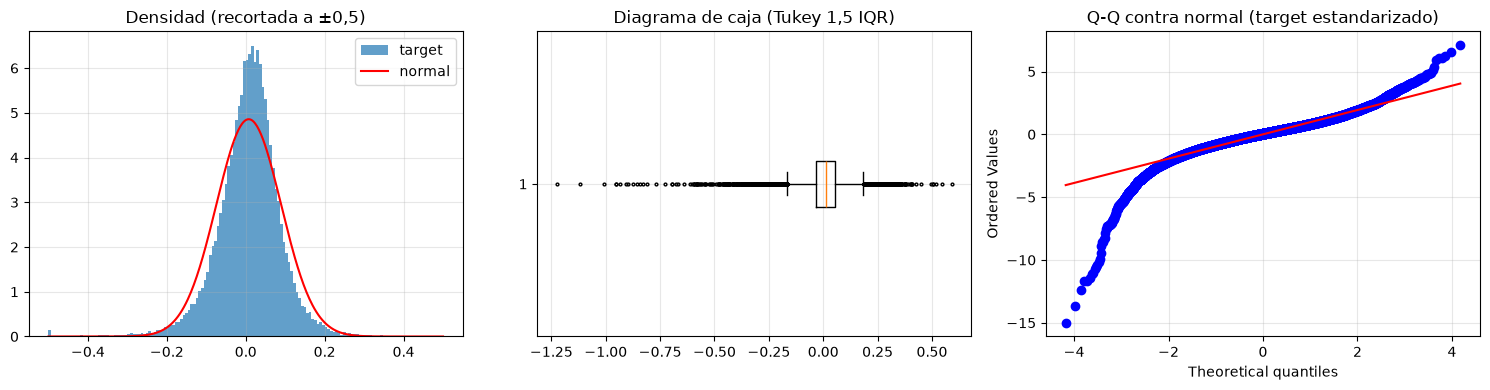

In [6]:
# Forma de la distribución del target y comparación con una normal.
q = y.quantile([.01, .05, .25, .5, .75, .95, .99])
z = (y - y.mean()) / y.std()
forma = pd.Series({'n': len(y), 'media': y.mean(), 'desviacion': y.std(), 'asimetria': y.skew(), 'curtosis_exceso': y.kurt(),
                   'pct_|z|>=3': (z.abs() >= 3).mean() * 100, 'pct_|z|>=3_normal': 2 * stats.norm.sf(3) * 100,
                   'pct_positivos': (y > 0).mean() * 100, 'jarque_bera_p': stats.jarque_bera(y).pvalue})
display(pd.concat([q.rename(lambda v: f'cuantil {v:g}'), forma]).to_frame('valor').round(4))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(y.clip(-0.5, 0.5), bins=150, density=True, alpha=0.7, label='target')
xs = np.linspace(-0.5, 0.5, 400); ax[0].plot(xs, stats.norm.pdf(xs, y.mean(), y.std()), 'r', label='normal')
ax[0].set_title('Densidad (recortada a ±0,5)'); ax[0].legend()
ax[1].boxplot(y, orientation='horizontal', whis=1.5, flierprops={'markersize': 2}); ax[1].set_title('Diagrama de caja (Tukey 1,5 IQR)')
stats.probplot(z, dist='norm', plot=ax[2]); ax[2].set_title('Q-Q contra normal (target estandarizado)')
plt.tight_layout(); guardar(fig, 'target_distribucion'); plt.show()

El mes explica el 34.5 % de la varianza del target; el 65.5 % es variacion entre acciones dentro del mes.
Dispersion entre acciones (desv. por mes): p10 0.046, mediana 0.060, p90 0.084, max 0.222 (objetivo de 202002)
Peor mes medio: objetivo de 202002 (-0.248); mejor: 202010 (0.134)


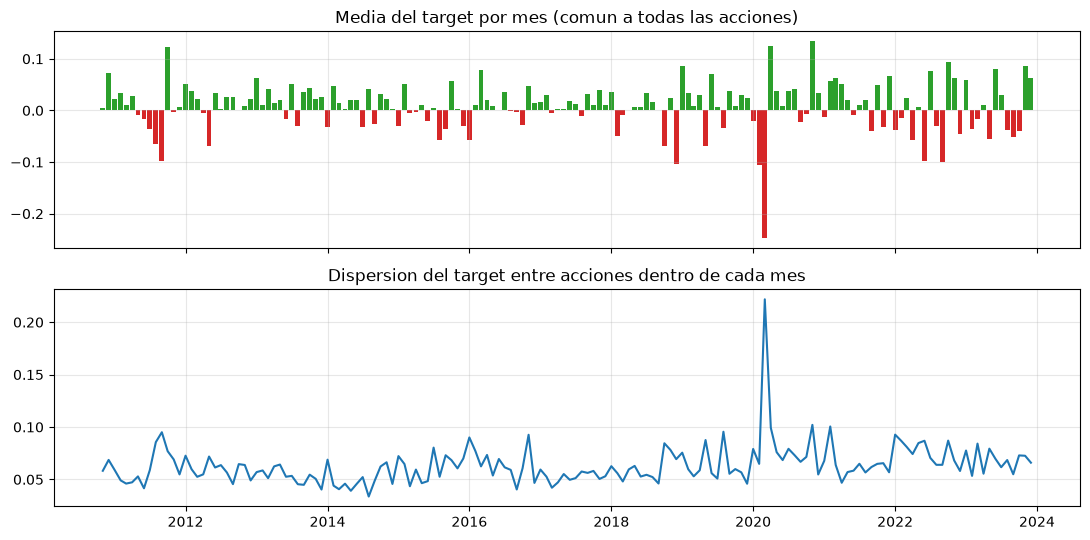

In [7]:
# Variación común del mes vs variación entre acciones (panel).
por_mes = train.groupby('anio_mes')[TARGET].agg(media='mean', dispersion='std', n='size')
fechas = pd.PeriodIndex(por_mes.index.astype(str), freq='M').to_timestamp() + pd.offsets.MonthBegin(1)  # mes del objetivo
entre = ((train.groupby('anio_mes')[TARGET].transform('mean') - y.mean()) ** 2).sum() / ((y - y.mean()) ** 2).sum()
print(f'El mes explica el {100 * entre:.1f} % de la varianza del target; el {100 * (1 - entre):.1f} % es variacion entre acciones dentro del mes.')
print(f"Dispersion entre acciones (desv. por mes): p10 {por_mes.dispersion.quantile(.1):.3f}, mediana {por_mes.dispersion.median():.3f}, "
      f"p90 {por_mes.dispersion.quantile(.9):.3f}, max {por_mes.dispersion.max():.3f} (objetivo de {por_mes.dispersion.idxmax()})")
print(f"Peor mes medio: objetivo de {por_mes.media.idxmin()} ({por_mes.media.min():.3f}); mejor: {por_mes.media.idxmax()} ({por_mes.media.max():.3f})")
fig, ax = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
ax[0].bar(fechas, por_mes.media, width=25, color=np.where(por_mes.media >= 0, 'tab:green', 'tab:red')); ax[0].set_title('Media del target por mes (comun a todas las acciones)')
ax[1].plot(fechas, por_mes.dispersion); ax[1].set_title('Dispersion del target entre acciones dentro de cada mes')
plt.tight_layout(); guardar(fig, 'target_por_mes'); plt.show()

## 5. Valores atípicos: IQR (diagrama de caja) y Z-score ≥ 3

Tukey: leve fuera de [Q1 − 1,5·IQR, Q3 + 1,5·IQR] y extremo fuera de 3·IQR. Z-score: |z| ≥ 3 (en una normal,
0,27 %). En retornos los extremos son reales (crisis, resultados trimestrales): se **miden y no se borran**; la
pregunta es qué métrica y qué transformación los toleran.

,pct_iqr_leve,pct_iqr_extremo,pct_z_ge_3,grupo,iqr_cero
volumen_prom_21d,8.77,4.26,1.50,PSet 2,False
dolares_negociados_prom_21d,9.39,4.19,2.05,PSet 2,False
vol_63d,5.77,2.38,2.15,PSet 2,False
obs_252d,2.35,2.35,1.53,PSet 2,True
cambio_rango_log_hl_mes,5.84,2.11,1.63,F1,False
vol_21d,5.02,1.87,1.73,PSet 2,False
nocturno_prom_21d,6.63,1.76,1.65,PSet 2,False
nocturno_log_mes,6.41,1.71,1.64,F1,False
vol_apertura_21d,4.98,1.69,1.75,PSet 2,False
rango_log_hl_prom_21d,4.61,1.53,1.55,F1,False


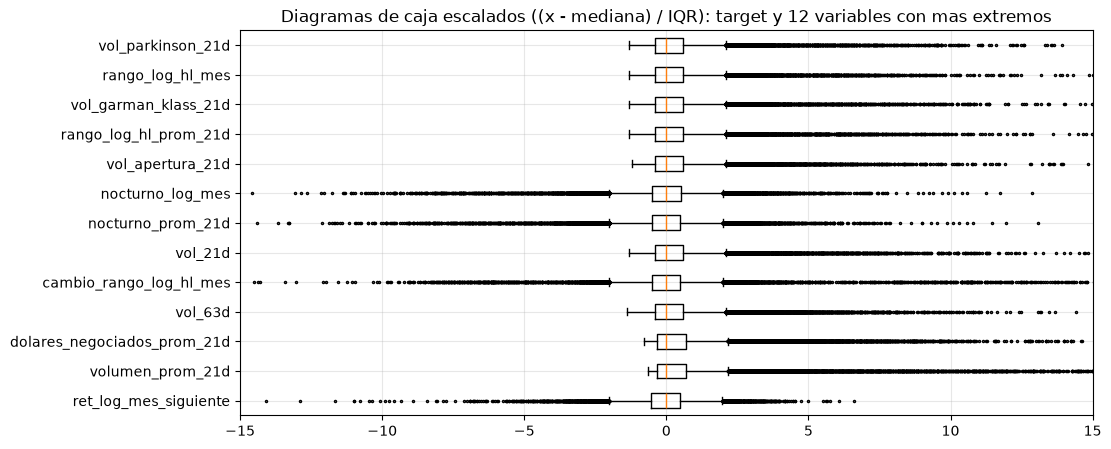

In [8]:
# Atípicos por variable: % IQR leve, % IQR extremo y % |z| >= 3.
X = train[FEATURES + [TARGET]]
q1, q3 = X.quantile(.25), X.quantile(.75); iqr = q3 - q1
fuera = lambda k: ((X < q1 - k * iqr) | (X > q3 + k * iqr)).mean() * 100
atip = pd.DataFrame({'pct_iqr_leve': fuera(1.5), 'pct_iqr_extremo': fuera(3.0),
                     'pct_z_ge_3': (((X - X.mean()) / X.std()).abs() >= 3).mean() * 100}).round(2)
atip['grupo'] = desc.grupo

atip['iqr_cero'] = iqr == 0   # p. ej. obs_252d casi siempre 252: cualquier otro valor cae fuera de la caja
top = atip.drop(TARGET)[~atip.iqr_cero.drop(TARGET)].sort_values('pct_iqr_extremo', ascending=False).head(12).index.tolist()
display(atip.sort_values('pct_iqr_extremo', ascending=False))
zs = (X[[TARGET] + top] - X[[TARGET] + top].median()) / iqr[[TARGET] + top]
fig, ax = plt.subplots(figsize=(11, 5))
ax.boxplot([zs[c].dropna() for c in zs], orientation='horizontal', whis=1.5, flierprops={'markersize': 1.5})
ax.set_yticks(range(1, zs.shape[1] + 1), zs.columns)
ax.set_xlim(-15, 15); ax.set_title('Diagramas de caja escalados ((x - mediana) / IQR): target y 12 variables con mas extremos')
guardar(fig, 'atipicos_boxplots'); plt.show()

## 6. Relación entre el target y las features: Pearson o Spearman

**Justificación.** Se usa **Spearman** como medida principal: el target y varias features tienen asimetría y
colas gruesas (secciones 3–5), y Pearson se deja arrastrar por pocos meses extremos; Spearman mide relación
monótona sobre rangos y no supone linealidad ni normalidad. Además el objetivo de negocio es **ordenar** acciones
para elegir cuáles comprar, que es exactamente lo que mide una correlación de rangos. Pearson se muestra al lado
para ver cuánto cambia.

Dos lecturas distintas en un panel:
- **Agrupada** (todas las filas juntas): mezcla el efecto del mes (mercado) con el de cada acción.
- **Dentro de cada mes** (IC, *information coefficient*): Spearman entre acciones del mismo mes, promediada en
  el tiempo, con su estadístico t. Es la señal útil para elegir acciones; las variables de mercado
  (iguales para todas las acciones del mes) no tienen IC.

Sin IC: mercado ['dispersion_mes', 'mes_obj_02', 'mes_obj_03', 'mes_obj_04', 'mes_obj_05', 'mes_obj_06', 'mes_obj_07', 'mes_obj_08', 'mes_obj_09', 'mes_obj_10', 'mes_obj_11', 'mes_obj_12', 'ret_log_nyse_composite_mes', 'ret_log_sp500_mes', 'rf_mes']; casi constantes en el mes ['obs_252d', 'dias_negociados_mes', 'ret_log_sp500_mes', 'ret_log_nyse_composite_mes', 'rf_mes']


,pearson,spearman,diferencia,ic_medio,ic_t,ic_pct_meses_positivo,grupo
ret_log_nyse_composite_mes,-0.0655,-0.0821,-0.0166,NaN,NaN,NaN,PSet 2
ret_log_sp500_mes,-0.0588,-0.0805,-0.0217,NaN,NaN,NaN,PSet 2
rango_log_hl_prom_21d,0.0928,0.0643,-0.0285,-0.0009,-0.0423,48.1013,F1
rango_log_hl_mes,0.0914,0.0622,-0.0292,-0.0004,-0.0206,48.1013,F1
vol_garman_klass_21d,0.0924,0.0613,-0.0311,0.0006,0.0291,49.3671,F1
vol_parkinson_21d,0.0870,0.0598,-0.0272,-0.0002,-0.0085,48.7342,F1
drawdown_252d,-0.0529,-0.0591,-0.0062,-0.0098,-0.4802,51.2658,PSet 2
ret_log_21d,-0.0515,-0.0586,-0.0071,-0.0186,-1.2619,45.5696,PSet 2
vol_21d,0.0779,0.0575,-0.0204,0.0009,0.0432,46.8354,PSet 2
ret_log_mes,-0.0504,-0.0569,-0.0066,-0.0205,-1.3712,46.2025,PSet 2


Spearman agrupado: max |rho| 0.082 (ret_log_nyse_composite_mes); IC: max |IC medio| 0.021 (exceso_sp500_log_mes), variables con |t| >= 2: 0 de 28


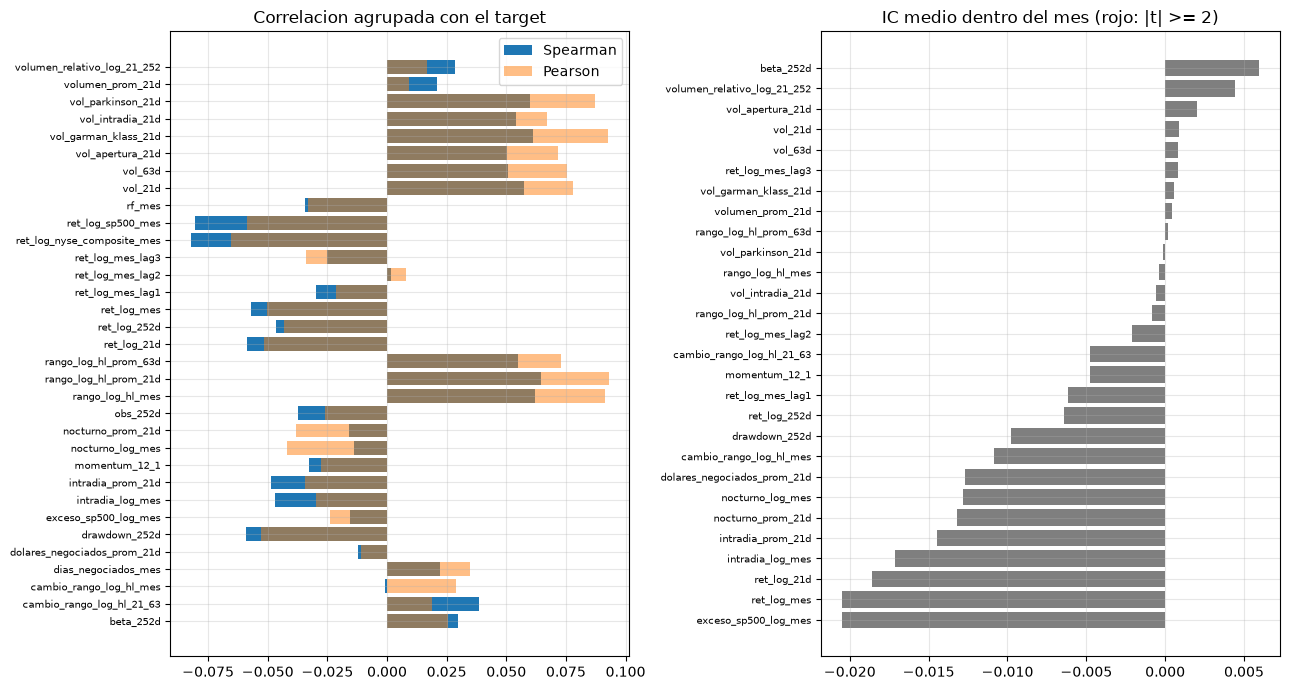

In [9]:
# Pearson vs Spearman agrupados, e IC (Spearman dentro de cada mes) con su t.
pear = train[FEATURES].corrwith(y); spear = train[FEATURES].corrwith(y, method='spearman')
# Sin IC: variables de mercado (iguales en el mes) y casi constantes dentro del mes (p. ej. dias_negociados_mes),
# cuyo rango solo tiene empates y daria un t enorme con un IC de 0.
casi_constantes = [c for c in FEATURES if train.groupby('anio_mes')[c].nunique().median() <= 3]
por_accion = [c for c in FEATURES if c not in DE_MERCADO and c not in casi_constantes]
print(f'Sin IC: mercado {sorted(DE_MERCADO)}; casi constantes en el mes {casi_constantes}')
rangos = train.groupby('anio_mes')[por_accion + [TARGET]].rank(pct=True)
rangos['anio_mes'] = train.anio_mes
ic_mes = rangos.groupby('anio_mes').apply(lambda g: g[por_accion].corrwith(g[TARGET]))
rel = pd.DataFrame({'pearson': pear, 'spearman': spear, 'diferencia': spear - pear,
                    'ic_medio': ic_mes.mean(), 'ic_t': ic_mes.mean() / ic_mes.std() * np.sqrt(ic_mes.notna().sum()),
                    'ic_pct_meses_positivo': (ic_mes > 0).mean() * 100})
rel['grupo'] = desc.grupo
display(rel.reindex(rel.spearman.abs().sort_values(ascending=False).index).round(4))
print(f"Spearman agrupado: max |rho| {rel.spearman.abs().max():.3f} ({rel.spearman.abs().idxmax()}); "
      f"IC: max |IC medio| {rel.ic_medio.abs().max():.3f} ({rel.ic_medio.abs().idxmax()}), "
      f"variables con |t| >= 2: {int((rel.ic_t.abs() >= 2).sum())} de {rel.ic_t.notna().sum()}")

orden = rel.ic_medio.dropna().sort_values()
fig, ax = plt.subplots(1, 2, figsize=(13, 7))
ax[0].barh(rel.index, rel.spearman, label='Spearman'); ax[0].barh(rel.index, rel.pearson, alpha=0.5, label='Pearson')
ax[0].set_title('Correlacion agrupada con el target'); ax[0].legend(); ax[0].tick_params(axis='y', labelsize=7)
ax[1].barh(orden.index, orden, color=np.where(rel.loc[orden.index, 'ic_t'].abs() >= 2, 'tab:red', 'tab:gray'))
ax[1].set_title('IC medio dentro del mes (rojo: |t| >= 2)'); ax[1].tick_params(axis='y', labelsize=7)
plt.tight_layout(); guardar(fig, 'relacion_target'); plt.show()

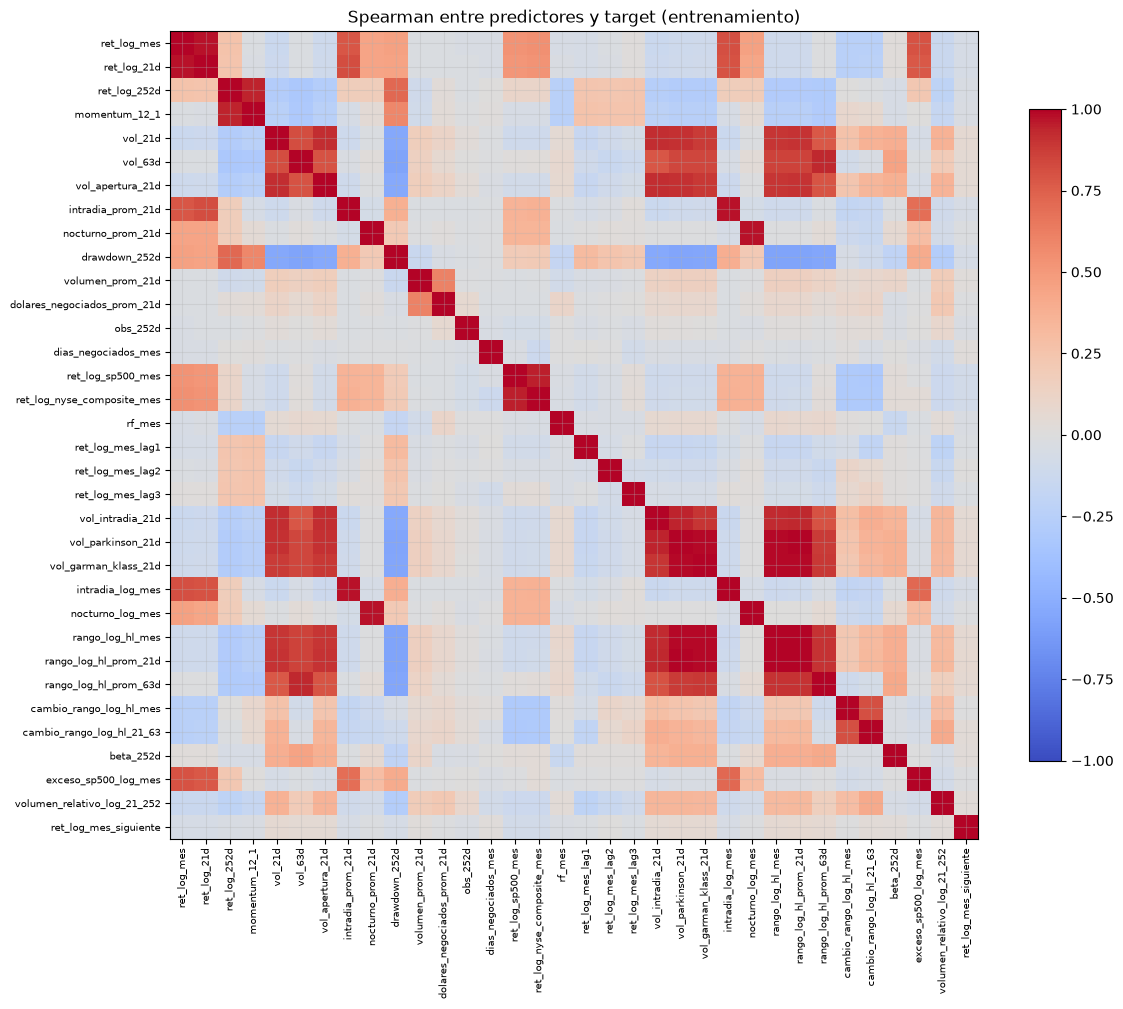

Pares de predictores con |rho| > 0,9: 23; > 0,8: 41


|rho|
rango_log_hl_mes      rango_log_hl_prom_21d       0.998
vol_parkinson_21d     rango_log_hl_prom_21d       0.993
                      vol_garman_klass_21d        0.992
                      rango_log_hl_mes            0.989
vol_garman_klass_21d  rango_log_hl_prom_21d       0.988
                      rango_log_hl_mes            0.985
nocturno_prom_21d     nocturno_log_mes            0.975
intradia_prom_21d     intradia_log_mes            0.973
ret_log_mes           ret_log_21d                 0.973
ret_log_sp500_mes     ret_log_nyse_composite_mes  0.948
ret_log_252d          momentum_12_1               0.945
vol_intradia_21d      vol_parkinson_21d           0.942
vol_63d               rango_log_hl_prom_63d       0.931
vol_intradia_21d      rango_log_hl_prom_21d       0.930
                      rango_log_hl_mes            0.927
vol_21d               vol_apertura_21d            0.918
                      vol_intradia_21d            0.916
vol_apertura_21d      vol_intradia_21d            0.915
                      vol_parkinson_21d           0.911
vol_21d               vol_parkinson_21d           0.909
rango_log_hl_mes      rango_log_hl_prom_63d       0.904
rango_log_hl_prom_21d rango_log_hl_prom_63d       0.903
vol_apertura_21d      rango_log_hl_prom_21d       0.900

In [10]:
# Mapa de calor de Spearman entre predictores y target, y pares casi redundantes.
corr = train[FEATURES + [TARGET]].corr(method='spearman')
fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=7); ax.set_yticks(range(len(corr)), corr.columns, fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.8); ax.set_title('Spearman entre predictores y target (entrenamiento)')
plt.tight_layout(); guardar(fig, 'correlacion_spearman'); plt.show()
a = corr.drop(index=TARGET, columns=TARGET).abs()
pares = a.where(np.triu(np.ones(a.shape, bool), 1)).stack().sort_values(ascending=False)
print(f'Pares de predictores con |rho| > 0,9: {int((pares > 0.9).sum())}; > 0,8: {int((pares > 0.8).sum())}')
display(pares[pares > 0.9].round(3).to_frame('|rho|'))

## 6b. Matriz de varianza-covarianza de la OBT

Covarianzas de todas las columnas numéricas de la OBT, **solo en entrenamiento** (corte en el tiempo: objetivo hasta 2023-12; el hold-out no entra) (se excluyen solo las de calendario
`anio_mes`, `anio`, `mes`; las columnas del futuro aparecen marcadas porque nunca son predictores). La diagonal
son las varianzas. Las escalas son muy distintas (volumen en millones de acciones frente a retornos del orden
de 0,01), así que el mapa usa una escala logarítmica con signo y las conclusiones se leen en la tabla de
varianzas y en la matriz de correlación (sección 6), que es la covarianza de las variables estandarizadas.

Matriz de 57 x 57 columnas numericas; solo entrenamiento: 46851 filas, meses 201010..202311, ultimo objetivo 2023-12 (hold-out excluido)


,varianza,desviacion,cov_con_target,uso
dolares_negociados_prom_21d,9.582e+16,3.095e+08,-2.72e+05,predictor
volumen_prom_21d,8.9e+13,9.434e+06,7218,predictor
precio_cierre_ajustado,3.551e+04,188.4,-0.1697,"clave, atributo o control"
obs_252d,18.3,4.278,-0.009145,predictor
tasa_irx_prom_mes_pct,2.187,1.479,-0.004782,"clave, atributo o control"
dias_negociados_mes,1.311,1.145,0.003286,predictor
beta_252d,0.1314,0.3626,0.0007557,predictor
cambio_rango_pct_hl_mes,0.1272,0.3566,0.001003,misma variable en % (EDA)
volumen_relativo_pct_21_252,0.08676,0.2945,0.0005461,misma variable en % (EDA)
volumen_relativo_log_21_252,0.06614,0.2572,0.0003531,predictor


Razon entre la mayor y la menor varianza: 6.29e+22


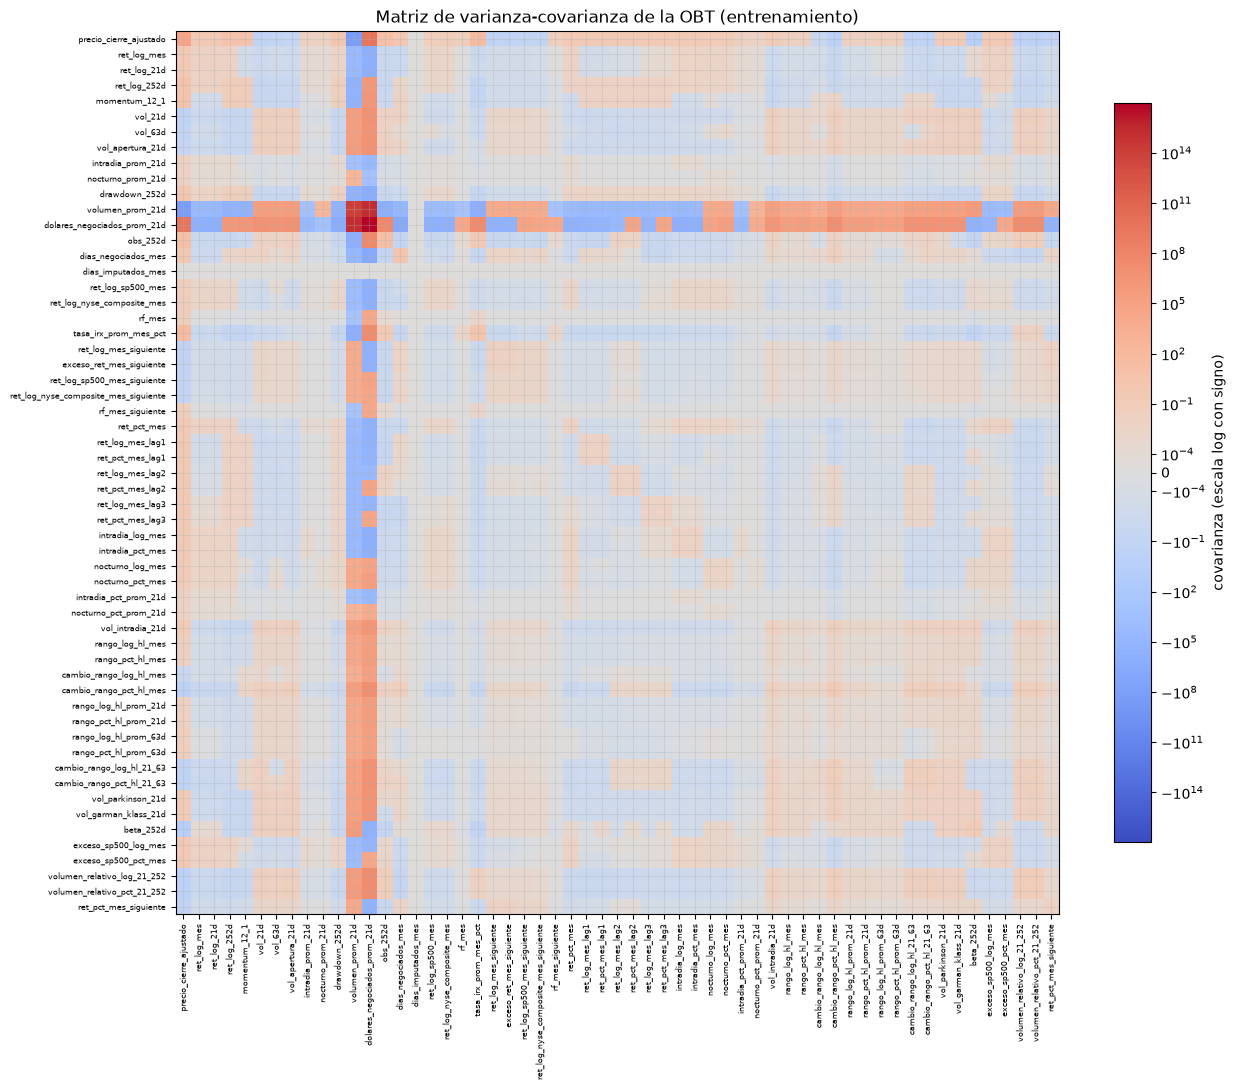

Predictores: rango 29 de 33 (dependencias lineales exactas: 4); numero de condicion sin ellas 38,518; 12 componentes principales explican el 90 % de la varianza estandarizada.
  combinacion exacta entre: exceso_sp500_log_mes , ret_log_sp500_mes , intradia_prom_21d , nocturno_prom_21d , ret_log_21d , nocturno_log_mes , intradia_log_mes
  combinacion exacta entre: ret_log_mes , ret_log_sp500_mes , nocturno_log_mes , intradia_log_mes , exceso_sp500_log_mes
  combinacion exacta entre: ret_log_252d , ret_log_21d , momentum_12_1
  combinacion exacta entre: ret_log_21d , exceso_sp500_log_mes , ret_log_sp500_mes , nocturno_log_mes , intradia_log_mes , nocturno_prom_21d , intradia_prom_21d


In [11]:
# Matriz de varianza-covarianza de las columnas numericas de la OBT (entrenamiento) y su lectura.
from matplotlib.colors import SymLogNorm
numericas = [c for c in obt.columns if pd.api.types.is_numeric_dtype(obt[c]) and not pd.api.types.is_bool_dtype(obt[c])
             and c not in ('anio_mes', 'anio', 'mes')]
cov = train[numericas].astype(float).cov()
print(f'Matriz de {cov.shape[0]} x {cov.shape[1]} columnas numericas; solo entrenamiento: {len(train)} filas, '
      f'meses {train.anio_mes.min()}..{train.anio_mes.max()}, ultimo objetivo {train.mes_objetivo.max()} (hold-out excluido)')
cov.to_csv(RAIZ / 'docs/covarianza_obt.csv')

varianzas = pd.DataFrame({'varianza': np.diag(cov), 'desviacion': np.sqrt(np.diag(cov)),
                          'cov_con_target': cov[TARGET], 'uso': [uso(c) for c in cov.index]}, index=cov.index)
with pd.option_context('display.float_format', '{:.4g}'.format):
    display(varianzas.sort_values('varianza', ascending=False))
print(f"Razon entre la mayor y la menor varianza: {varianzas.varianza.max() / varianzas.varianza[varianzas.varianza > 0].min():.2e}")

fig, ax = plt.subplots(figsize=(13, 11))
lim = np.nanmax(np.abs(cov.values))
im = ax.imshow(cov, cmap='coolwarm', norm=SymLogNorm(linthresh=1e-4, vmin=-lim, vmax=lim))
ax.set_xticks(range(len(cov)), cov.columns, rotation=90, fontsize=6); ax.set_yticks(range(len(cov)), cov.index, fontsize=6)
fig.colorbar(im, ax=ax, shrink=0.8, label='covarianza (escala log con signo)')
ax.set_title('Matriz de varianza-covarianza de la OBT (entrenamiento)'); plt.tight_layout(); guardar(fig, 'covarianza'); plt.show()

# Condicionamiento de los predictores: correlacion (covarianza estandarizada) y sus autovalores.
autoval, autovec = np.linalg.eigh(train[FEATURES].dropna().corr().values)
nulos = autoval < 1e-8                      # direcciones sin varianza: combinaciones lineales exactas
rango = int((~nulos).sum())
var_exp = np.sort(autoval)[::-1].cumsum() / autoval.sum()
print(f'Predictores: rango {rango} de {len(FEATURES)} (dependencias lineales exactas: {int(nulos.sum())}); '
      f'numero de condicion sin ellas {autoval[~nulos].max() / autoval[~nulos].min():,.0f}; '
      f'{int((var_exp < 0.90).sum()) + 1} componentes principales explican el 90 % de la varianza estandarizada.')
dependencias = []
for k in np.flatnonzero(nulos):
    carga = pd.Series(autovec[:, k], index=FEATURES)
    dependencias.append(' , '.join(carga[carga.abs() > 0.1].sort_values().index))
    print(f'  combinacion exacta entre: {dependencias[-1]}')

## 6c. Matriz de varianza-covarianza de las variables normalizadas

Cada columna numérica se normaliza con su media y desviación **de entrenamiento** (corte en el tiempo: el hold-out no entra) (z = (x − media) / desviación,
lo mismo que hace `StandardScaler` dentro del Pipeline). La covarianza de variables normalizadas es, por
definición, la **correlación de Pearson**: la diagonal vale 1 y cada celda está entre −1 y 1, así que las
columnas se pueden comparar entre sí aunque sus escalas originales difieran en 22 órdenes de magnitud (6b).

Matriz 56 x 56; diagonal entre 1.0000 y 1.0000; maxima diferencia con la correlacion de Pearson: 2.0e-12


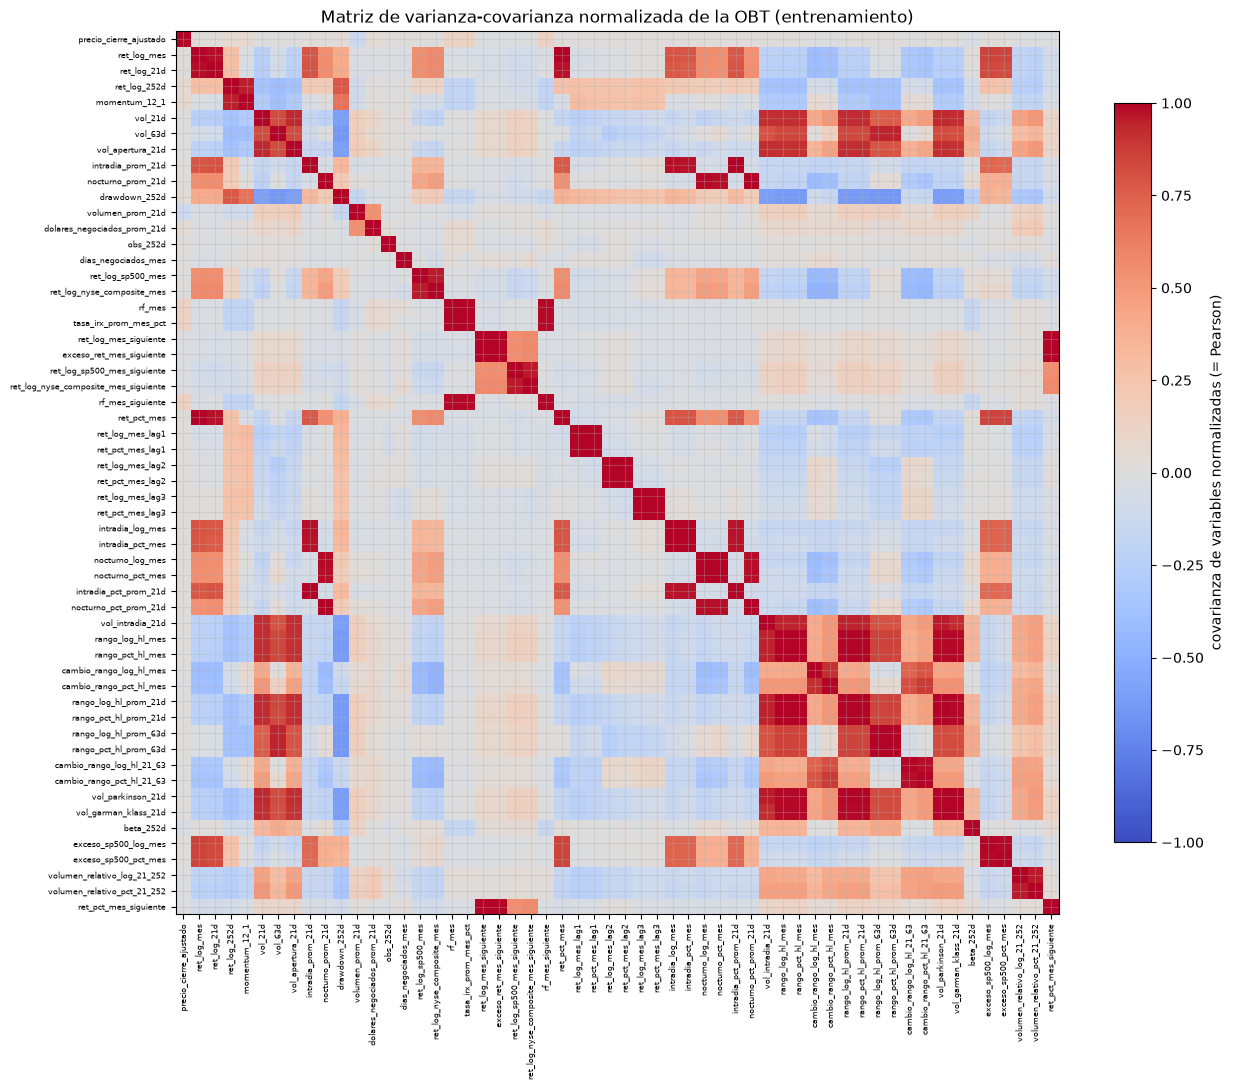

Mayor covarianza normalizada con el target: {'exceso_ret_mes_siguiente': 1.0, 'ret_pct_mes_siguiente': 0.993, 'ret_log_nyse_composite_mes_siguiente': 0.577, 'ret_log_sp500_mes_siguiente': 0.553, 'rango_pct_hl_prom_21d': 0.095, 'rango_pct_hl_mes': 0.093}
Diferencia con Spearman en las mismas variables (secc. 6), primeras 5: {'rango_log_hl_prom_21d': -0.029, 'vol_garman_klass_21d': -0.031, 'rango_log_hl_mes': -0.029, 'vol_parkinson_21d': -0.027, 'vol_21d': -0.02}


In [12]:
# Covarianza de las columnas numericas normalizadas (z-score con media y desviacion de entrenamiento).
Z = train[numericas].astype(float)
Z = (Z - Z.mean()) / Z.std()
Z = Z.loc[:, Z.std() > 0]                       # sin columnas constantes (no se pueden normalizar)
cov_z = Z.cov()
cov_z.to_csv(RAIZ / 'docs/covarianza_normalizada_obt.csv')
pearson = train[cov_z.columns].astype(float).corr()
print(f'Matriz {cov_z.shape[0]} x {cov_z.shape[1]}; diagonal entre {np.diag(cov_z).min():.4f} y {np.diag(cov_z).max():.4f}; '
      f'maxima diferencia con la correlacion de Pearson: {np.nanmax(np.abs(cov_z.values - pearson.values)):.1e}')

fig, ax = plt.subplots(figsize=(13, 11))
im = ax.imshow(cov_z, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(cov_z)), cov_z.columns, rotation=90, fontsize=6); ax.set_yticks(range(len(cov_z)), cov_z.index, fontsize=6)
fig.colorbar(im, ax=ax, shrink=0.8, label='covarianza de variables normalizadas (= Pearson)')
ax.set_title('Matriz de varianza-covarianza normalizada de la OBT (entrenamiento)'); plt.tight_layout()
guardar(fig, 'covarianza_normalizada'); plt.show()

con_target = cov_z[TARGET].drop(TARGET).sort_values(key=np.abs, ascending=False)
print('Mayor covarianza normalizada con el target:', con_target.head(6).round(3).to_dict())
print('Diferencia con Spearman en las mismas variables (secc. 6), primeras 5:',
      (rel.reindex(con_target.index).spearman - con_target).dropna().head(5).round(3).to_dict())

## 7. Desbalance de clases

No aplica: el problema es de **regresión** (retorno continuo). Como referencia para una métrica direccional
(acertar el signo), se reporta la proporción de retornos positivos en la sección 4.

## 8. Calidad heredada del pipeline

Resumen de lo que el análisis de calidad del pipeline encontró y de las banderas que llegan a la OBT de
entrenamiento.

In [13]:
# Banderas de calidad en entrenamiento y hallazgos del notebook de calidad (si ya se corrio contra Snowflake).
banderas = pd.Series({'filas con dias imputados': int((train.dias_imputados_mes > 0).sum()),
                      'filas con tramo excluido en el mes': int(train.hubo_tramo_excluido_mes.fillna(False).sum()),
                      'filas con retorno diario extremo (|r| > 0,4)': int(train.hubo_retorno_extremo_mes.fillna(False).sum()),
                      'filas con bolsa desconocida (ya no cotiza)': int(train.bolsa_desconocida.fillna(False).sum()),
                      'filas cuyo objetivo cruza el corte': int(train.objetivo_cruza_corte.fillna(False).sum())})
display(banderas.to_frame('filas de entrenamiento'))
hq = RAIZ / 'pipeline/docs/calidad/analisis_pipeline/hallazgos.csv'
if hq.exists():
    with pd.option_context('display.max_colwidth', 160):
        display(pd.read_csv(hq)[['hallazgo', 'evidencia']])
else:
    print('Correr pipeline/docs/calidad/analisis_calidad_pipeline.ipynb para ver los hallazgos de calidad.')

,filas de entrenamiento
filas con dias imputados,0
filas con tramo excluido en el mes,0
"filas con retorno diario extremo (|r| > 0,4)",15
filas con bolsa desconocida (ya no cotiza),80
filas cuyo objetivo cruza el corte,0


,hallazgo,evidencia
0,"RAW tiene cargas repetidas de la misma (ticker, fecha)","23,276 filas en 4,048 claves repetidas; Bronze queda con 1,845,167 filas y 0 duplicados"
1,Quedan valores invalidos despues de Silver,"invalidos por capa {'RAW': 563, 'BRONZE': 4, 'SILVER': 2, 'GOLD': 2, 'CALIDAD': 0, 'OBT': 0}; columnas: SILVER.SLV_ACCIONES.TICKER (1), SILVER.SLV_MEMBRESIA..."
2,No hubo dias imputados en esta corrida,"0 de 1,832,433 dias de Silver"
3,2 predictores tienen nulos aun en filas elegibles,cambio_rango_log_hl_21_63 0.02 % (ventana de 63 dias: historia corta); volumen_relativo_log_21_252 0.00 % (ventana de 252 dias: historia corta)
4,El objetivo tiene colas mas gruesas que una normal,"curtosis en exceso 8.3 (normal: 0); 1.24 % con |z| >= 3 (normal: 0,27 %); 0.51 % fuera de 3 IQR (elegibles)"
5,Quedan dias con apertura o cierre fuera del rango minimo-maximo,"Silver: maximo < minimo 0, cierre fuera 0, apertura fuera 5; en RAW (acciones) apertura fuera 39"
6,La tasa libre de riesgo se rellena algunos dias,"2 de 4,245 dias con ^IRX rellenada"


## 9. Hallazgos que afectan el modelado

Se calculan con los números de arriba; si cambia el snapshot, cambian. Se guardan en `docs/hallazgos_eda.csv`
y las figuras en `docs/figuras/eda_*.png` para el documento técnico.

In [14]:
# Hallazgo -> evidencia -> consecuencia en el modelo.
H = []
def agrega(h, e, c): H.append({'hallazgo': h, 'evidencia': e, 'consecuencia': c})
agrega('Target con colas gruesas y asimetria negativa',
       f"curtosis en exceso {y.kurt():.1f} y asimetria {y.skew():.2f}; {forma['pct_|z|>=3']:.2f} % con |z| >= 3 (normal: 0,27 %); "
       f"{atip.loc[TARGET, 'pct_iqr_leve']:.2f} % fuera de 1,5 IQR; cuantiles 1 % y 99 %: {q[.01]:.3f} y {q[.99]:.3f}",
       'Metrica tecnica principal MAE (con RMSE como secundaria) e IC de Spearman para el ranking; no borrar extremos; '
       'probar modelos robustos (arboles, perdida Huber) y comparar con y sin winsorizar el target solo en entrenamiento.')
agrega('Gran parte de la varianza es comun a todas las acciones del mes',
       f'el mes explica el {100 * entre:.1f} % de la varianza del target; dispersion entre acciones entre {por_mes.dispersion.quantile(.1):.3f} y {por_mes.dispersion.quantile(.9):.3f} (p10-p90)',
       'Validacion por meses completos con purga (nunca KFold aleatorio de filas); evaluar el ranking dentro de cada mes (IC) '
       'y usar el rango transversal de las features (RangoTransversal) para que el modelo aprenda que acciones ganan a las otras, no el mercado. '
       'Para el MAE el nivel del mes importa: features de mes dispersion_mes y mes calendario del objetivo (notebook 02).')
n_sig = int((rel.ic_t.abs() >= 2).sum())
agrega('La senal para ordenar acciones dentro del mes es debil',
       f'Spearman agrupado max {rel.spearman.abs().max():.3f} ({rel.spearman.abs().idxmax()}), pero IC medio dentro del mes max '
       f'{rel.ic_medio.abs().max():.3f} ({rel.ic_medio.abs().idxmax()}); {n_sig} de {rel.ic_t.notna().sum()} variables con |t| >= 2',
       'Esperar mejoras modestas sobre las lineas base; la correlacion agrupada esta inflada por el efecto del mes. '
       'Comparar con pruebas de significancia entre pliegues (Diebold-Mariano, Wilcoxon) y regularizar.')
agrega('Predictores casi redundantes',
       f"{int((pares > 0.9).sum())} pares con |rho| > 0,9, p. ej. {', '.join(f'{a}~{b}' for a, b in pares.index[:3])}; "
       f"rango {rango} de {len(FEATURES)}: {len(dependencias)} combinaciones lineales exactas por construccion ({' | '.join(dependencias)})",
       'Seleccion de variables dentro del Pipeline (SelectKBest ajustado por pliegue) y modelos regularizados; en modelos lineales sin '
       'regularizacion quitar una variable de cada combinacion exacta (decision de features, notebook 02); no interpretar coeficientes uno a uno.')
v = train.vol_63d
agrega('La escala de riesgo cambia mucho entre acciones y en el tiempo',
       f'vol_63d anualizada: p10 {v.quantile(.1):.3f}, p90 {v.quantile(.9):.3f} (razon {v.quantile(.9) / v.quantile(.1):.1f}x)',
       'Escalado dentro del Pipeline; las derivadas normalizadas por riesgo (momentum_por_riesgo, vol_relativa) se probaron en 02 y no bajan el MAE.')
falt_pred = f_tr.drop(TARGET)
agrega('Casi no hay faltantes en los datos de entrenamiento',
       f"{int((falt_pred > 0).sum())} de {len(falt_pred)} predictores con nulos tras excluir {', '.join(EXCLUIDAS)} (maximo {falt_pred.max():.3f} %)",
       'Huecos intermedios: interpolacion lineal por accion a cada lado del corte; inicio o final: mediana dentro del Pipeline. '
       'No hace falta descartar variables por faltantes.')
agrega('BMS y AMCR quedan fuera del analisis (H19)',
       f"{len(ex)} filas elegibles de la OBT ({ex.anio_mes.min()}..{ex.anio_mes.max()}); AMCR 2012-2014 con barras de solo cierre",
       'La semilla equivalencias_tickers trata la compra de Bemis por Amcor como cambio de simbolo; corregir en el pipeline (H19).')
planas = train[(train.vol_21d == 0) | (train.volumen_prom_21d == 0)]
if len(planas):
    agrega('Hay filas elegibles con precio plano y sin volumen',
           f"{len(planas)} fila(s): " + ', '.join(f'{r.ticker} {r.anio_mes}' for r in planas.head(5).itertuples()) + ' con vol_21d = 0 o volumen_prom_21d = 0',
           'Parecen datos de relleno de la fuente (sin negociacion real): excluirlas en elegible (pipeline) o en preparar(); revisar la accion en Yahoo.')
hallazgos = pd.DataFrame(H)
with pd.option_context('display.max_colwidth', 220):
    display(hallazgos)
hallazgos.to_csv(RAIZ / 'docs/hallazgos_eda.csv', index=False)
print(f'Guardado docs/hallazgos_eda.csv y {len(list(FIG.glob("eda_*.png")))} figuras en docs/figuras/.')

,hallazgo,evidencia,consecuencia
0,Target con colas gruesas y asimetria negativa,"curtosis en exceso 9.6 y asimetria -1.02; 1.27 % con |z| >= 3 (normal: 0,27 %); 3.85 % fuera de 1,5 IQR; cuantiles 1 % y 99 %: -0.223 y 0.204","Metrica tecnica principal MAE (con RMSE como secundaria) e IC de Spearman para el ranking; no borrar extremos; probar modelos robustos (arboles, perdida Huber) y comparar con y sin winsorizar el target solo en entren..."
1,Gran parte de la varianza es comun a todas las acciones del mes,el mes explica el 34.5 % de la varianza del target; dispersion entre acciones entre 0.046 y 0.084 (p10-p90),Validacion por meses completos con purga (nunca KFold aleatorio de filas); evaluar el ranking dentro de cada mes (IC) y usar el rango transversal de las features (RangoTransversal) para que el modelo aprenda que acci...
2,La senal para ordenar acciones dentro del mes es debil,"Spearman agrupado max 0.082 (ret_log_nyse_composite_mes), pero IC medio dentro del mes max 0.021 (exceso_sp500_log_mes); 0 de 28 variables con |t| >= 2","Esperar mejoras modestas sobre las lineas base; la correlacion agrupada esta inflada por el efecto del mes. Comparar con pruebas de significancia entre pliegues (Diebold-Mariano, Wilcoxon) y regularizar."
3,Predictores casi redundantes,"23 pares con |rho| > 0,9, p. ej. rango_log_hl_mes~rango_log_hl_prom_21d, vol_parkinson_21d~rango_log_hl_prom_21d, vol_parkinson_21d~vol_garman_klass_21d; rango 29 de 33: 4 combinaciones lineales exactas por construcc...","Seleccion de variables dentro del Pipeline (SelectKBest ajustado por pliegue) y modelos regularizados; en modelos lineales sin regularizacion quitar una variable de cada combinacion exacta (decision de features, note..."
4,La escala de riesgo cambia mucho entre acciones y en el tiempo,"vol_63d anualizada: p10 0.148, p90 0.413 (razon 2.8x)","Escalado dentro del Pipeline; las derivadas normalizadas por riesgo (momentum_por_riesgo, vol_relativa) se probaron en 02 y no bajan el MAE."
5,Casi no hay faltantes en los datos de entrenamiento,"0 de 33 predictores con nulos tras excluir BMS, AMCR (maximo 0.000 %)",Huecos intermedios: interpolacion lineal por accion a cada lado del corte; inicio o final: mediana dentro del Pipeline. No hace falta descartar variables por faltantes.
6,BMS y AMCR quedan fuera del analisis (H19),109 filas elegibles de la OBT (201303..202610); AMCR 2012-2014 con barras de solo cierre,La semilla equivalencias_tickers trata la compra de Bemis por Amcor como cambio de simbolo; corregir en el pipeline (H19).


Guardado docs/hallazgos_eda.csv y 9 figuras en docs/figuras/.
